# <center>Exploratory Data Analysis on the

# <center>Automobiles Dataset

### <center>Report

---------------------------------------------------------------------------

EDA Report on Automobiles

This report explores the automobile dataset, which contains information about the following:

* Different vehicles
* Manufacturer
* Fuel type
* Body style
* Engine characteristics
* Fuel economy
* Price.

The goal of this analysis is to clean and sanitise the dataset, remove incomplete entries, correct data types, and explore the relationships between different features of the listed vehicles.

In [1]:
# Import libraries

import numpy as np
import pandas as pd
import seaborn as sns

from datetime import datetime
import matplotlib.pyplot as plt
%matplotlib inline

The dataset is loaded from the `automobile.txt` file.

The file already contains column headers, so we do not need to manually assign column names. However, the dataset uses `?` to represent missing values. To make pandas recognise these as missing values, we'll use `na_values="?"` when reading in the file.

In [5]:
# Load the automobile dataset

columns = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
    "bore", "stroke", "compression-ratio", "horsepower",
    "peak-rpm", "city-mpg", "highway-mpg", "price"
]

automobiles_df = pd.read_csv("automobile.txt", na_values="?")

# Clean column names
automobiles_df.columns = automobiles_df.columns.str.strip()

automobiles_df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


### Data Cleaning

Identify columns that are redundant or unnecessary. For the automobile dataset, we'll remove the `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [6]:
automobiles_df.drop(['normalized-losses', 'symboling'], axis=1, inplace=True)

### Remove any duplicate rows

Duplicate rows can distort the analysis by causing multiple errors, such as allowing the same vehicle record to be counted more than once.

We'll check for duplicate rows and remove them if any are present.

In [7]:
print("Duplicate rows before cleaning:")
print(automobiles_df.duplicated().sum())

automobiles_df = automobiles_df.drop_duplicates()

print("\nDuplicate rows after cleaning:")
print(automobiles_df.duplicated().sum())

Duplicate rows before cleaning:
0

Duplicate rows after cleaning:
0


#### Removing Rows with Missing Data

The dataset uses “?” to represent missing values in several columns.

When loading the dataset, `na_values="?"` was used so that Pandas could automatically recognise these placeholders as missing values (`NaN`).

All rows containing missing values were then removed from the dataframe to ensure that only complete records were used for analysis.

While this improves data consistency and reliability, it also reduces the sample size and may remove some potentially useful observations.

In [8]:
print("Shape before removing missing values:")
print(automobiles_df.shape)

# Drop rows with missing values
automobiles_df.dropna(inplace=True)

print("\nShape after removing missing values:")
print(automobiles_df.shape)

print("\nRemaining missing values:")
print(automobiles_df.isnull().sum())

Shape before removing missing values:
(205, 24)

Shape after removing missing values:
(193, 24)

Remaining missing values:
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [9]:
import numpy as np

int_columns = [
    "horsepower",
    "peak-rpm",
    "price"
]

for col in int_columns:
    automobiles_df[col] = pd.to_numeric(automobiles_df[col])
    automobiles_df[col] = automobiles_df[col].astype(np.int64)

print(automobiles_df.dtypes)

make                     str
fuel-type                str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower             int64
peak-rpm               int64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object


### Finding Certain Categories
Locate all automobiles in the "hatchback" body style.

In [11]:
hatchback_cars = automobiles_df[automobiles_df['body-style'] == 'hatchback']
print(hatchback_cars.head())

           make fuel-type aspiration num-of-doors body-style drive-wheels  \
2   alfa-romero       gas        std          two  hatchback          rwd   
18    chevrolet       gas        std          two  hatchback          fwd   
19    chevrolet       gas        std          two  hatchback          fwd   
21        dodge       gas        std          two  hatchback          fwd   
22        dodge       gas        std          two  hatchback          fwd   

   engine-location  wheel-base  length  width  ...  engine-size  fuel-system  \
2            front        94.5   171.2   65.5  ...          152         mpfi   
18           front        88.4   141.1   60.3  ...           61         2bbl   
19           front        94.5   155.9   63.6  ...           90         2bbl   
21           front        93.7   157.3   63.8  ...           90         2bbl   
22           front        93.7   157.3   63.8  ...           90         2bbl   

    bore stroke  compression-ratio horsepower  peak-rpm 

#### Which are the 5 most expensive cars?

In the below visualisations, we'll compare the five most expensive cars in the dataset with the five cheapest cars to better understand how price differences reflect vehicle positioning.

By examining these opposite ends, we can explore whether higher-priced cars appear to offer better overall value to customers.

To break this explanation down further, we'll also compare the fuel efficiency (measured by highway MPG) of these vehicles to analyse whether more expensive cars are necessarily more economical to run.

In [12]:
# Create a clear car label
automobiles_df["car_label"] = (
    automobiles_df["make"] + " - " +
    automobiles_df["body-style"] + " #" +
    automobiles_df.index.astype(str)
)

# Get top 5 most expensive cars
top_5_expensive = automobiles_df.sort_values(
    by="price",
    ascending=False
).head(5)

# Get top 5 cheapest cars
top_5_cheapest = automobiles_df.sort_values(
    by="price",
    ascending=True
).head(5)



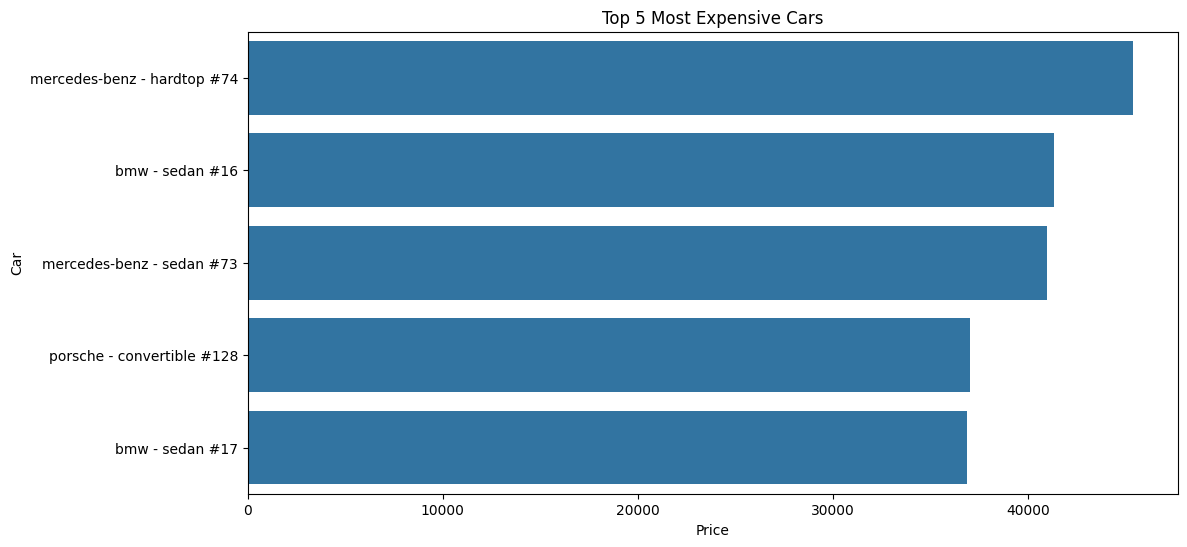

In [13]:
# Graph 1: Top 5 most expensive cars

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_5_expensive,
    x="price",
    y="car_label"
)

plt.title("Top 5 Most Expensive Cars")
plt.xlabel("Price")
plt.ylabel("Car")

plt.show()

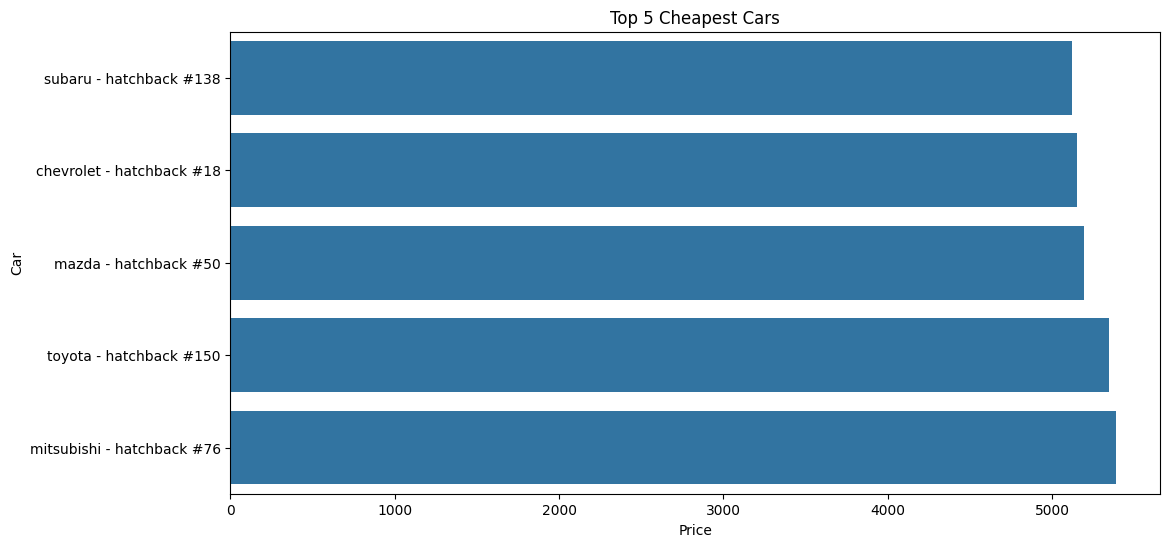

In [14]:
# Graph 2: Top 5 cheapest cars

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_5_cheapest,
    x="price",
    y="car_label"
)

plt.title("Top 5 Cheapest Cars")
plt.xlabel("Price")
plt.ylabel("Car")

plt.show()

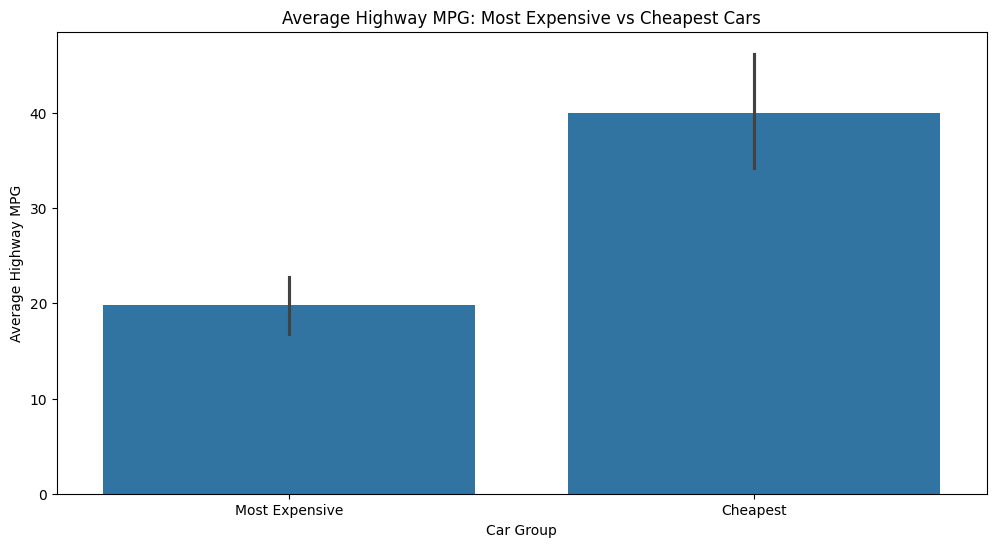

In [15]:
# Graph 3: Compare fuel economy of most expensive vs cheapest cars

top_5_expensive = top_5_expensive.copy()
top_5_cheapest = top_5_cheapest.copy()

top_5_expensive["price_group"] = "Most Expensive"
top_5_cheapest["price_group"] = "Cheapest"

comparison_df = pd.concat([top_5_expensive, top_5_cheapest])

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="price_group",
    y="highway-mpg"
)

plt.title("Average Highway MPG: Most Expensive vs Cheapest Cars")
plt.xlabel("Car Group")
plt.ylabel("Average Highway MPG")

plt.show()

### Key Findings

The visualisations reveal clear differences between the most expensive and cheapest cars in the dataset.

The most expensive cars are typically premium or luxury vehicles, such as Mercedes-benz, BMW, and Porsche. These cars are often associated with performance, branding, and advanced features rather than fuel efficiency alone.

By contrast, the cheapest cars tend to prioritise affordability and, in many cases, deliver similar or even superior fuel economy.

This suggests that a higher price does not automatically mean better fuel efficiency. Instead, expensive cars may justify their cost through luxury, design, engineering, or performance, while cheaper cars may offer stronger value for budget-conscious buyers focused on running costs.

#### Which manufacturer builds the most fuel efficient vehicles?

To determine which manufacturer produces the most fuel-efficient vehicles, we'll compare the average highway MPG (miles per gallon) across all manufacturers in the dataset.

By grouping vehicles according to make and calculating the mean fuel economy, we can identify which brands generally prioritise fuel efficiency.

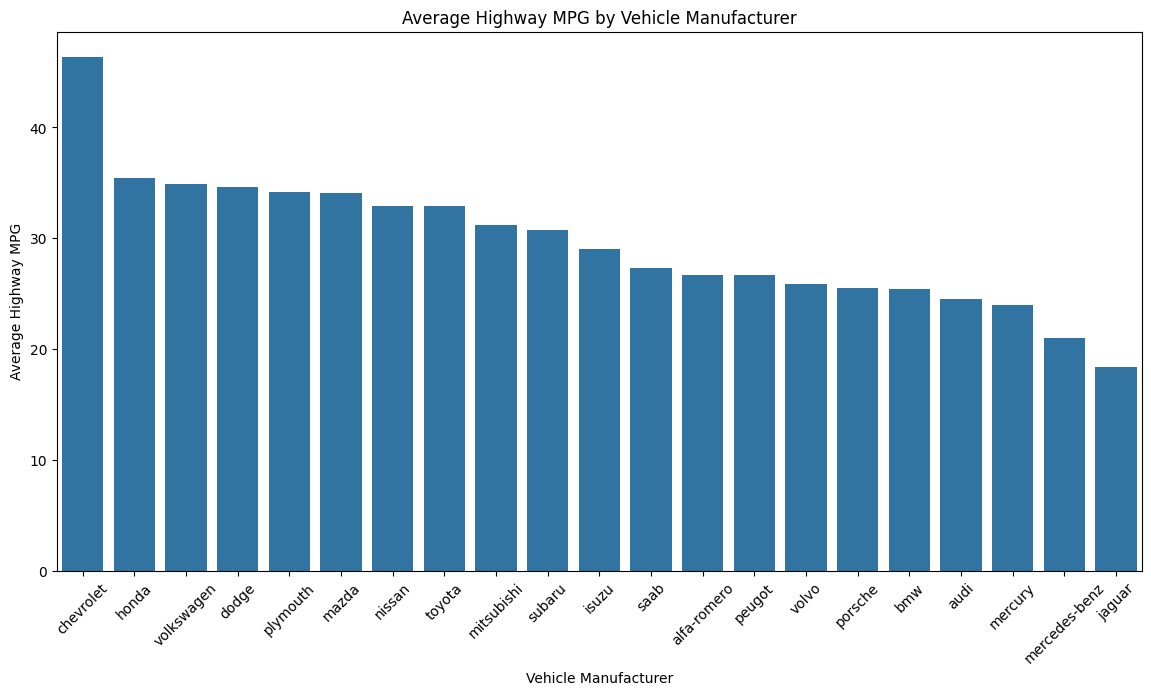

In [16]:
# Sort manufacturers by average highway MPG
manufacturer_mpg = (
    automobiles_df.groupby("make")["highway-mpg"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=manufacturer_mpg,
    x="make",
    y="highway-mpg",
    errorbar=None
)

plt.title("Average Highway MPG by Vehicle Manufacturer")
plt.xlabel("Vehicle Manufacturer")
plt.ylabel("Average Highway MPG")

plt.xticks(rotation=45)

plt.show()

### Key Findings

The visualisation highlights clear differences in fuel efficiency between manufacturers.

Manufacturers with the highest average highway MPG appear to be makes that are considered more 'average', and prioritise fuel economy, likely focusing on smaller or more practical vehicles.

By contrast, manufacturers with lower average MPG are considered more 'luxurious', and may produce heavier and performance-focused where fuel efficiency is less of a priority.

This comparison demonstrates how manufacturer design priorities can strongly influence overall vehicle efficiency.

#### Which vehicles have the largest engine capacity?

To identify which vehicles have the largest engine capacity, the dataset was sorted by the `engine-size` column in descending order.

This helps reveal which vehicles prioritise larger engine performance, which may also relate to horsepower, price, and fuel efficiency.

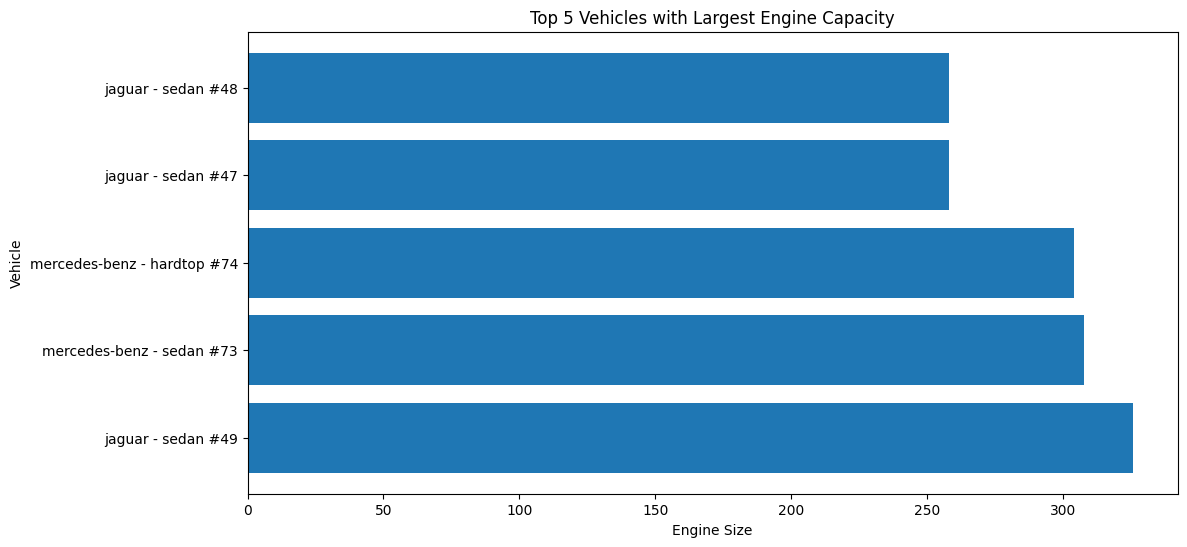

In [18]:
largest_engine_cars = (
    automobiles_df.sort_values(by="engine-size", ascending=False)
    .head(5)
)

plt.figure(figsize=(12, 6))

plt.barh(
    largest_engine_cars["car_label"],
    largest_engine_cars["engine-size"]
)

plt.title("Top 5 Vehicles with Largest Engine Capacity")
plt.xlabel("Engine Size")
plt.ylabel("Vehicle")

plt.show()



### Key Findings

The vehicles with the largest engine sizes are likely concentrated among premium, luxury, or performance-oriented manufacturers.

Large engine capacity often reflects stronger performance potential, but it may also be associated with higher fuel consumption and increased vehicle cost.

This suggests that engine size is an important feature when evaluating the trade-off between power, efficiency, and price.

#### Which vehicle manufacturer has the most car models in the dataset

This visualisation shows which vehicle manufacturers have the highest number of car models represented in the dataset.

This helps identify which brands are most heavily featured and may provide insight into manufacturer diversity or market presence.

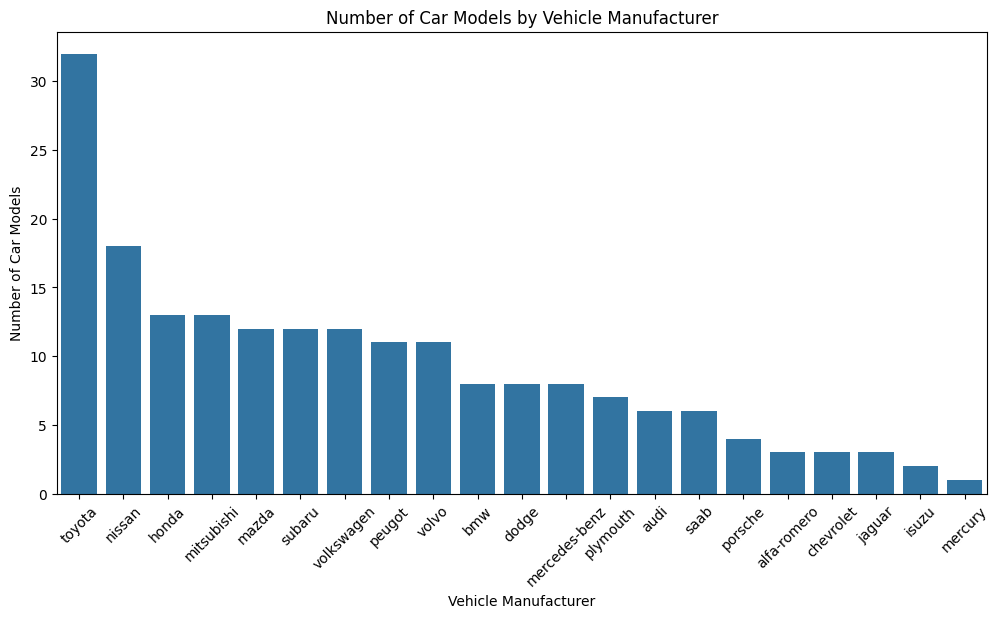

In [19]:
manufacturer_counts = (
    automobiles_df["make"]
    .value_counts()
    .reset_index()
)

# Rename columns clearly
manufacturer_counts.columns = ["make", "count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=manufacturer_counts,
    x="make",
    y="count",
    errorbar=None
)

plt.title("Number of Car Models by Vehicle Manufacturer")
plt.xlabel("Vehicle Manufacturer")
plt.ylabel("Number of Car Models")

plt.xticks(rotation=45)

plt.show()

### Key Findings

Toyota appears with the strongest results as the brand with the most volume of cars in the datset. Manufacturers with the highest number of models appear to have broader product ranges or stronger representation in the sample.

A larger number of models may indicate greater market diversity, while manufacturers with fewer models may be more specialised or less represented in this dataset.

### Is there a correlation between engine size and price?

In this visualisation, we'll explore whether vehicles with larger engine sizes tend to have higher prices.

Engine size is often associated with performance and cost, so analysing this relationship can help determine whether engine capacity is a strong contributor to vehicle pricing.

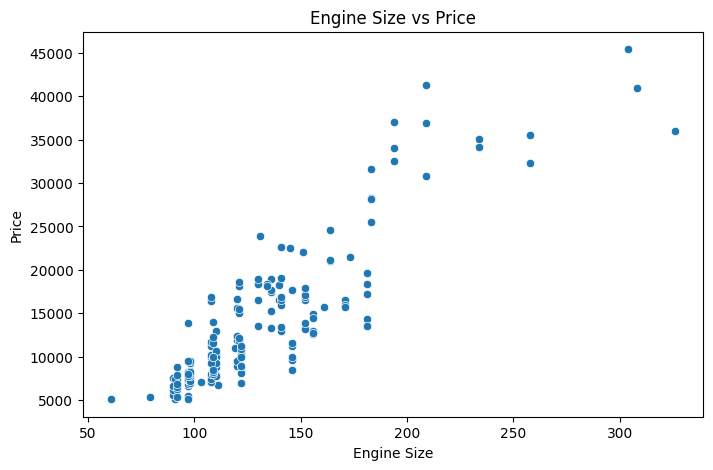

In [21]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=automobiles_df, x="engine-size", y="price")

plt.title("Engine Size vs Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")

plt.show()

### Key Findings

The scatter plot suggests a direct relationship between engine size and vehicle price.

In general, vehicles with larger engines tend to be more expensive, which may reflect higher performance capabilities, increased production costs, or high-end market positioning.

While the relationship is not perfectly linear, engine size appears to be an important factor associated with higher automobile prices.

### Final Conclusions

Mercedes-Benz, Porsche, and BMW take the top spots as the most expensive cars in the dataset, clearly sitting on the luxury side of the market. On the other end, brands like Subaru, Chevrolet, and Mazda appear among the cheapest options, offering more affordable choices for everyday drivers.

When comparing fuel efficiency between these groups, the cheaper cars generally perform better, with noticeably higher highway MPG. In simple terms, they can travel further on less fuel than the more expensive cars. This suggests that more affordable vehicles often focus on practicality, lower running costs, and efficiency, which can make them a smart choice for buyers who are budget-conscious but still want reliable performance.

Chevrolet stands out as one of the most fuel-efficient manufacturers overall, with Honda and Volkswagen also ranking highly. In contrast, many of the more expensive manufacturers from earlier visualisations fall lower on the fuel-efficiency scale, showing that luxury and performance often come at the cost of higher fuel consumption.

Jaguar and Mercedes-Benz also appear among the cars with the largest engine sizes, which likely reflects a stronger focus on power and performance. Toyota, meanwhile, has the highest number of vehicles in the dataset, suggesting a wide market presence and a broad variety of models.

There is also a clear relationship between engine size and price: larger engines tend to appear in more expensive vehicles, while smaller engines are more common in cheaper cars. This could mean that bigger engines increase both production costs and performance value, which then pushes up the final price.

Overall, this dataset shows that more expensive cars are not always the most practical choice. While they may offer luxury, power, or status, cheaper cars often provide better fuel efficiency and stronger everyday value. This makes the “best” car largely dependent on what the buyer values most.

<b> This report was written by: </b> Ally Remas